# Supplementary Figure S7. Controls and pair-type breakdown for the improvement of flagged base pairs after re-refinement and re-determination

In [1]:
import json
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import Normalize

def _root() -> Path:
    here = Path.cwd().resolve()
    for base in [here, *here.parents]:
        if (base / "data").is_dir() and (base / "notebooks").is_dir():
            return base
    raise RuntimeError("run this from inside the analysis repo")

ROOT = _root()
data_file = lambda rel: ROOT / "data" / rel
_json = lambda rel: json.loads(data_file(rel).read_text())

def save(fig, rel):
    path = ROOT / rel
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path)
    return path

plt.rcParams.update({
    "figure.dpi": 130, "savefig.dpi": 300, "savefig.bbox": "tight",
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica Neue", "Helvetica", "DejaVu Sans"],
    "font.size": 8.5, "axes.labelsize": 9, "axes.titlesize": 9,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8,
    "axes.linewidth": 0.8, "xtick.major.width": 0.8, "ytick.major.width": 0.8,
    "xtick.direction": "out", "ytick.direction": "out",
    "axes.grid": False, "legend.frameon": False,
    "pdf.fonttype": 42, "ps.fonttype": 42,
})
BLUE, ORANGE, GREEN, RED, GREY = "#4C72B0", "#DD8452", "#55A868", "#C44E52", "0.55"
POINT_FACE, POINT_EDGE, FIT = "#C9C9C9", "0.15", "#111111"

CUT = 80.0

LW = ["cWW", "tWW", "cWH", "tWH", "cWS", "tWS", "cHH", "tHH", "cHS", "tHS", "cSS", "tSS"]
TOOLS = ["parse", "fr3d", "rnaview", "barnaba", "rnapolis", "bpnet"]
TOOL_LABELS = ["FastRNA", "FR3D", "RNAView", "barnaba", "RNApolis", "BPNET"]

def finish(ax):
    for side in ("top", "right", "bottom", "left"):
        ax.spines[side].set_visible(True)
        ax.spines[side].set_linewidth(0.8)
    ax.grid(False)
    ax.tick_params(direction="out", width=0.8, length=3.5)
    return ax

def letter(fig, ax, s, dx=-0.030, dy=0.012):
    box = ax.get_position()
    fig.text(box.x0 + dx, box.y1 + dy, s, fontsize=13, fontweight="bold",
             ha="left", va="bottom")

def pair_scores() -> pd.DataFrame:
    return pd.read_json(data_file("reference/scores/pair_scores_uniques_parse.jsonl"), lines=True)

def scored_pairs(lw_only=True) -> pd.DataFrame:
    df = pair_scores()
    df = df[~df["is_ambiguous"].fillna(False) & df["score"].notna()].copy()
    return df[df["lw_class"].isin(LW)].copy() if lw_only else df

def _resolution(m):
    if not isinstance(m, dict):
        return None
    return (m.get("EM Diffraction Resolution (Å)") or m.get("Refinement_resolution")
            or m.get("EM Resolution (Å)"))

def structure_scores() -> pd.DataFrame:
    sc = _json("reference/scores/scores_all_uniques.json")["scores"]
    md = _json("reference/metadata/metadata_cache.json")
    vm, nt = md["validation_metrics"], md["nucleotide_counts"]
    rows = []
    for pdb, info in sc.items():
        m = vm.get(pdb) if isinstance(vm.get(pdb), dict) else {}
        rows.append({"pdb": pdb, "pairs_score": info.get("pairs_score"),
                     "backbone_suiteness": info.get("backbone_suiteness"),
                     "n_pairs": info.get("n_pairs", 0),
                     "n_residues_scored": info.get("n_residues_scored", 0),
                     "method": m.get("Experimental_method"),
                     "resolution": _resolution(m), "clashscore": m.get("clashscore"),
                     "rnasuiteness": m.get("rnasuiteness"),
                     "n_nucleotides": nt.get(pdb),
                     "deposited": m.get("Deposition_Date")})
    return pd.DataFrame(rows)

def runtime() -> pd.DataFrame:
    df = pd.read_csv(data_file("benchmark/dssr_PARSE_time_benchmark.csv"))
    df = df[(df["Nucleotides"] > 0) & (df["dssr_avg"] > 0) & (df["parse_avg"] > 0)].copy()
    df["ratio"] = df["dssr_avg"] / df["parse_avg"]
    return df

WEIGHTS = _json("reference/scoring_tables/penalty_weights.json")["penalty_weights"]
ISSUES = list(WEIGHTS)
ISSUE_LABELS = {"distance": "H-bond distance", "hbond_angles": "H-bond angles",
                "incorrect_hbond_count": "H-bond count", "stretch": "Stretch",
                "opening": "Opening", "stagger": "Stagger", "propeller": "Propeller",
                "shear": "Shear", "buckle": "Buckle", "clash": "Clash"}

def hist_grid(fig, spec, df, params, xlabel, cols=3):
    rows = int(np.ceil(len(params) / cols))
    sub = spec.subgridspec(rows, cols, wspace=0.42, hspace=0.62)
    axes = []
    for i, p in enumerate(params):
        ax = fig.add_subplot(sub[i // cols, i % cols])
        vals = pd.to_numeric(df[p], errors="coerce").dropna()
        if len(vals) > 20000:
            vals = vals.sample(20000, random_state=1)
        ax.hist(vals, bins=40, color=BLUE, alpha=0.8)
        ax.set_xlabel(p.replace("_", " "), fontsize=7.5)
        ax.tick_params(labelsize=6.5)
        if i % cols == 0:
            ax.set_ylabel("Count", fontsize=7.5)
        finish(ax)
        axes.append(ax)
    return axes

AXIS_LABEL_PT = 8.5


def enlarge_axis_labels(fig, text_pt=7.0, axis_pt=AXIS_LABEL_PT):
    for ax in fig.axes:
        for lab in (ax.xaxis.label, ax.yaxis.label):
            if lab.get_text().strip():
                lab.set_fontsize(lab.get_fontsize() * axis_pt / text_pt)


## Panel setup
Time-reversal block


In [2]:
REDO = _json("validation/time_reversal_controls.json")["thresholds"][f"{CUT:g}"]
RES = _json("validation/time_reversal_resolved.json")

for tag, blk in (("PDB-REDO", REDO), ("re-solved", RES)):
    a = blk["asymmetry"]
    print(f"{tag:9s} units {blk['n_units']:4d} | "
          f"forward {blk['forward']['mean']:+6.2f} "
          f"[{blk['forward']['ci95'][0]:+.2f}, {blk['forward']['ci95'][1]:+.2f}] | "
          f"reverse {blk['reverse']['mean']:+6.2f} "
          f"[{blk['reverse']['ci95'][0]:+.2f}, {blk['reverse']['ci95'][1]:+.2f}] | "
          f"asymmetry {a['mean']:+6.2f} "
          f"[{a['ci95'][0]:+.2f}, {a['ci95'][1]:+.2f}]  P(<=0)={a['p_le_0']:.3f}")
print("\nimplied true improvement, re-solved: "
      f"{RES['implied_true_improvement']['mean']:+.2f} "
      f"[{RES['implied_true_improvement']['ci95'][0]:+.2f}, "
      f"{RES['implied_true_improvement']['ci95'][1]:+.2f}]")

REDO_PAIRS = pd.DataFrame(_json("validation/pdb_redo_pairs_comparison.json")["pairs"])


PDB-REDO  units  210 | forward +10.64 [+9.52, +11.75] | reverse  -0.43 [-1.27, +0.46] | asymmetry +11.07 [+9.51, +12.58]  P(<=0)=0.000
re-solved units   60 | forward +17.07 [+15.00, +19.22] | reverse  +9.11 [+6.36, +11.96] | asymmetry  +7.95 [+5.09, +10.90]  P(<=0)=0.000

implied true improvement, re-solved: +3.98 [+2.55, +5.45]


## Panel A
Mean score change, forward versus time-reversed, for the PDB-REDO and re-solved cohorts


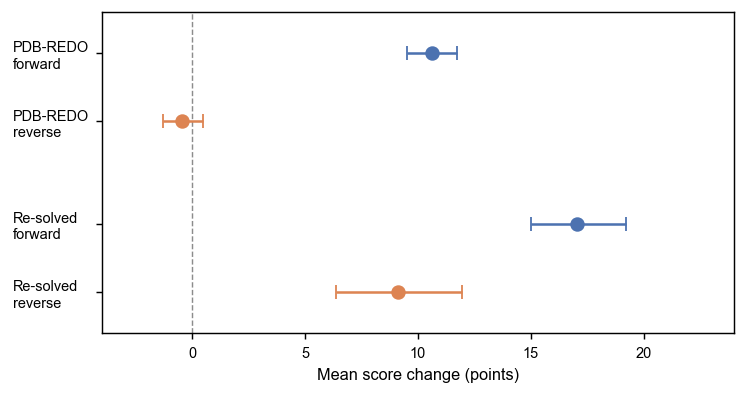

In [3]:
def left_align_yticklabels(ax):
    fig = ax.figure
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    labels = ax.get_yticklabels()
    for t in labels:
        t.set_horizontalalignment("left")
        t.set_multialignment("left")
    width = max(t.get_window_extent(renderer).width for t in labels) * 72 / fig.dpi
    ax.yaxis.set_tick_params(pad=width + plt.rcParams["ytick.major.pad"])


def draw_a(ax):
    rows = [("PDB-REDO\nforward", REDO["forward"], BLUE),
            ("PDB-REDO\nreverse", REDO["reverse"], ORANGE),
            ("Re-solved\nforward", RES["forward"], BLUE),
            ("Re-solved\nreverse", RES["reverse"], ORANGE)]
    ys = [3.5, 2.5, 1.0, 0.0]
    ax.axvline(0, color="0.55", lw=0.8, ls="--", zorder=1)
    for y, (_, d, colour) in zip(ys, rows):
        lo, hi = d["ci95"]
        ax.errorbar(d["mean"], y, xerr=[[d["mean"] - lo], [hi - d["mean"]]], fmt="o",
                    color=colour, ecolor=colour, capsize=4, markersize=7,
                    elinewidth=1.4, zorder=3)
    ax.set_yticks(ys, [r[0] for r in rows], fontsize=8)
    ax.set_ylim(-0.6, 4.1)
    ax.set_xlim(-4, 24)
    ax.set_xlabel("Mean score change (points)")
    finish(ax)
    left_align_yticklabels(ax)


fig, ax = plt.subplots(figsize=(5.8, 3.1))
draw_a(ax)
fig.tight_layout()
save(fig, "figures/supplemental/figS7_A_time_reversed_delta.png")
plt.show()


## Panel B
The already-perfect structures: what re-refinement does when there is nothing to fix


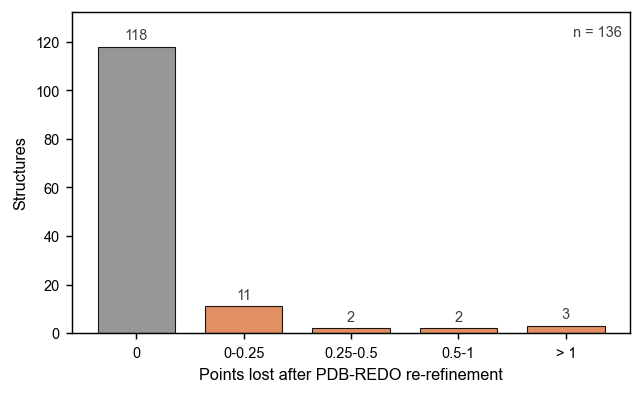

136 structures with every matched pair at 100 before re-refinement
  unchanged: 118 (87%) | mean change -0.059 | largest drop -2.04


In [4]:
STRUCT_100 = (REDO_PAIRS.groupby("pdb_id")
              .agg(before=("orig_score", "mean"), after=("redo_score", "mean"),
                   n=("orig_score", "size")))
STRUCT_100 = STRUCT_100[STRUCT_100.before >= 99.999]
LOSS_BINS = [-0.001, 0.001, 0.25, 0.5, 1.0, np.inf]
LOSS_LABELS = ["0", "0-0.25", "0.25-0.5", "0.5-1", "> 1"]

def draw_b(ax):
    loss = 100 - STRUCT_100.after
    counts = pd.cut(loss, bins=LOSS_BINS, labels=LOSS_LABELS).value_counts().reindex(LOSS_LABELS)
    ax.bar(np.arange(len(LOSS_LABELS)), counts.to_numpy(), width=0.72,
           color=[GREY] + [ORANGE] * (len(LOSS_LABELS) - 1), alpha=0.9,
           edgecolor="black", linewidth=0.6)
    for i, v in enumerate(counts.to_numpy()):
        ax.text(i, v + counts.max() * 0.015, f"{v}", ha="center", va="bottom",
                fontsize=8, color="0.25")
    ax.text(0.985, 0.96, f"n = {len(STRUCT_100)}", transform=ax.transAxes,
            ha="right", va="top", fontsize=8, color="0.25")
    ax.set_xticks(np.arange(len(LOSS_LABELS)), LOSS_LABELS)
    ax.set_ylim(0, counts.max() * 1.12)
    ax.set_xlabel("Points lost after PDB-REDO re-refinement")
    ax.set_ylabel("Structures")
    finish(ax)
    return counts


fig, ax = plt.subplots(figsize=(5.0, 3.1))
counts = draw_b(ax)
fig.tight_layout()
save(fig, "figures/supplemental/figS7_B_already_perfect.png")
plt.show()

loss = 100 - STRUCT_100.after
print(f"{len(STRUCT_100)} structures with every matched pair at 100 before re-refinement")
print(f"  unchanged: {int((loss < 0.001).sum())} ({(loss < 0.001).mean():.0%}) | "
      f"mean change {-loss.mean():+.3f} | largest drop {-loss.max():+.2f}")

## Panel setup
Canonical and noncanonical pairs under re-modelling

In [5]:
CANON = {"AU", "UA", "GC", "CG"}
GROUPS = ["canonical", "noncanonical"]

REDO_PAIRS["group"] = np.where((REDO_PAIRS.lw_class == "cWW") & REDO_PAIRS.bp_type.isin(CANON),
                               "canonical", "noncanonical")

RES_PAIRS = pd.read_csv(data_file("reference/resolved_again/resolve_pairs_matched.csv"))
_bp = RES_PAIRS.base1.astype(str) + RES_PAIRS.base2.astype(str)
RES_PAIRS["group"] = np.where((RES_PAIRS.lw_class == "cWW") & _bp.isin(CANON),
                              "canonical", "noncanonical")

for tag, df, before, after in (("PDB-REDO", REDO_PAIRS, "orig_score", "redo_score"),
                               ("re-solved", RES_PAIRS, "score_w", "score_b")):
    for gp in GROUPS:
        f = df[(df.group == gp) & (df[before] < CUT)]
        print(f"{tag:9s} {gp:12s} flagged {len(f):5,d}  median {f[before].median():5.1f} -> "
              f"{f[after].median():5.1f}  left Review tier {100 * (f[after] >= CUT).mean():3.0f}%")


def flagged_violins(ax, df, before, after, after_label):
    ax.axhspan(0, CUT, color="0.94", zorder=0)
    pos, gap = [], 0.0
    for gp in GROUPS:
        f = df[(df.group == gp) & (df[before] < CUT)]
        for k, (col, colour) in enumerate(((before, BLUE), (after, ORANGE))):
            x = gap + k * 0.9
            vp = ax.violinplot(f[col], positions=[x], widths=0.8, showextrema=False)
            for b in vp["bodies"]:
                b.set_facecolor(colour); b.set_edgecolor("0.25")
                b.set_linewidth(0.6); b.set_alpha(0.85)
            q1, med, q3 = np.percentile(f[col], [25, 50, 75])
            ax.vlines(x, q1, q3, color="0.15", lw=3, zorder=3)
            ax.scatter([x], [med], s=22, color="white", edgecolor="0.15", lw=0.8, zorder=4)
        pos.append(gap + 0.45)
        gap += 2.4
    ax.set_xticks(pos)
    ax.set_xticklabels(["Canonical", "Non-canonical"], fontsize=9)
    ax.set_ylim(20, 102)
    ax.set_ylabel("Base-pair score")
    ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=BLUE),
                       plt.Rectangle((0, 0), 1, 1, color=ORANGE)],
              labels=["original", after_label], loc="lower right")
    finish(ax)


PDB-REDO  canonical    flagged 1,987  median  71.4 ->  90.8  left Review tier  70%
PDB-REDO  noncanonical flagged   180  median  74.0 ->  76.6  left Review tier  41%
re-solved canonical    flagged   885  median  72.4 -> 100.0  left Review tier  86%
re-solved noncanonical flagged   217  median  74.7 ->  94.6  left Review tier  74%


## Panel C
Flagged canonical and noncanonical pairs before and after PDB-REDO re-refinement

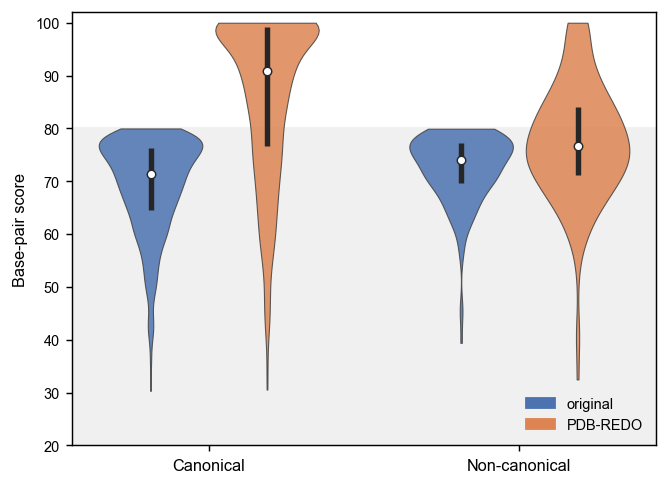

In [6]:
def draw_c(ax):
    flagged_violins(ax, REDO_PAIRS, "orig_score", "redo_score", "PDB-REDO")


fig, ax = plt.subplots(figsize=(5.2, 3.8))
draw_c(ax)
fig.tight_layout()
save(fig, "figures/supplemental/figS7_C_redo_canonical_noncanonical.png")
plt.show()


## Panel D
Flagged canonical and noncanonical pairs before and after re-solving from better data

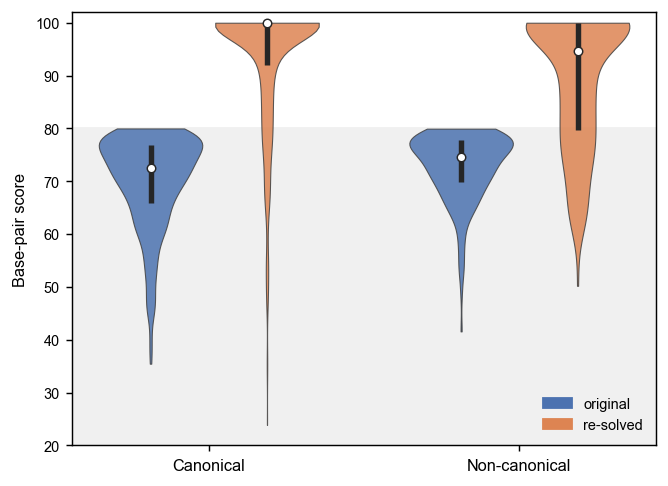

In [7]:
def draw_d(ax):
    flagged_violins(ax, RES_PAIRS, "score_w", "score_b", "re-solved")


fig, ax = plt.subplots(figsize=(5.2, 3.8))
draw_d(ax)
fig.tight_layout()
save(fig, "figures/supplemental/figS7_D_resolved_canonical_noncanonical.png")
plt.show()


## Combined figure


text scaled x1.03: 7 pt prints at 7.1 pt at page width


axis titles print at 8.5 pt and panel letters at 12.0 pt (6.84 in saved, shown at 6.73 in)


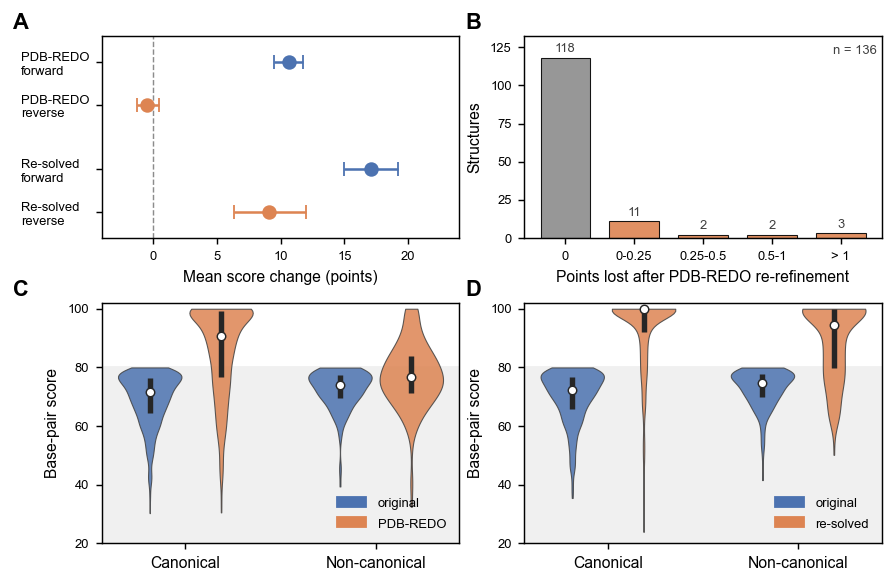

In [8]:
LABEL_IN, COL_GAP, ROW_GAP = 0.66, 0.50, 0.50
COL_W = (6.66 - LABEL_IN - COL_GAP) / 2
X1, X2 = LABEL_IN, LABEL_IN + COL_W + COL_GAP
H_AB, H_CD = 1.55, 1.85
Y_AB = 0.25
Y_CD = Y_AB + H_AB + ROW_GAP
FIG_W, FIG_H = X2 + COL_W + 0.06, Y_CD + H_CD + 0.40
fig = plt.figure(figsize=(FIG_W, FIG_H))
inch = lambda x, y, w, h: [x / FIG_W, 1 - (y + h) / FIG_H, w / FIG_W, h / FIG_H]
ax_a = fig.add_axes(inch(X1, Y_AB, COL_W, H_AB)); ax_b = fig.add_axes(inch(X2, Y_AB, COL_W, H_AB))
ax_c = fig.add_axes(inch(X1, Y_CD, COL_W, H_CD)); ax_d = fig.add_axes(inch(X2, Y_CD, COL_W, H_CD))
draw_a(ax_a); draw_b(ax_b); draw_c(ax_c); draw_d(ax_d)
fig.canvas.draw()
_r = fig.canvas.get_renderer(); _inv = fig.transFigure.inverted()
_x_left = min(a.get_tightbbox(_r).transformed(_inv).x0 for a in (ax_a, ax_c))
for ax, s in ((ax_a, "A"), (ax_b, "B"), (ax_c, "C"), (ax_d, "D")):
    x = _x_left if s in "AC" else ax.get_tightbbox(_r).transformed(_inv).x0
    y = max(ax.get_position().y1, ax.get_tightbbox(_r).transformed(_inv).y1)
    fig.text(x, y + 0.006, s, fontsize=12, fontweight="bold", ha="left", va="bottom")
import matplotlib.text as mtext
for _t in fig.findobj(mtext.Text):
    if _t in fig.texts and _t.get_fontweight() in ("bold", 700) and len(_t.get_text().strip()) <= 2:
        _t.set_fontsize(12)
    else:
        _t.set_fontsize(7)
enlarge_axis_labels(fig)
for _ax in fig.axes:
    _ax.xaxis.label.set_fontsize(7)
    _ax.yaxis.label.set_fontsize(7)
import matplotlib.text as _mtext
def _print_scale(fig, page_in=6.73, pad=0.08):
    fig.canvas.draw()
    bb = fig.get_tightbbox(fig.canvas.get_renderer())
    return max(1.0, (bb.width + 2 * pad) / page_in)
fig.canvas.draw()
_texts = [t for t in fig.findobj(_mtext.Text) if t.get_text().strip()]
_base = {t: t.get_fontsize() for t in _texts}
_s = 1.0
for _ in range(6):
    _need = _print_scale(fig)
    if _s >= _need - 1e-3:
        break
    _s = _need * 1.01
    for _t in _texts:
        _t.set_fontsize(_base[_t] * _s)
print(f"text scaled x{_s:.2f}: 7 pt prints at {7 * _s / _print_scale(fig):.1f} pt "
      f"at page width")
left_align_yticklabels(ax_a)
def _set_print_sizes(fig, axis_pt=8.5, letter_pt=12.0, page_in=6.73, pad=0.08):
    letters = [t for t in fig.texts if t.get_text().strip().isalpha()
               and t.get_text().strip().isupper() and len(t.get_text().strip()) <= 2
               and t.get_fontweight() in ("bold", 700)]
    for _ in range(8):
        fig.canvas.draw()
        bb = fig.get_tightbbox(fig.canvas.get_renderer())
        shrink = max(1.0, (bb.width + 2 * pad) / page_in)
        for ax in fig.axes:
            for lab in (ax.xaxis.label, ax.yaxis.label):
                if lab.get_text().strip():
                    lab.set_fontsize(axis_pt * shrink)
        for t in letters:
            t.set_fontsize(letter_pt * shrink)
    print(f"axis titles print at {axis_pt} pt and panel letters at {letter_pt} pt "
          f"({bb.width + 2 * pad:.2f} in saved, shown at {min(page_in, bb.width + 2 * pad):.2f} in)")


_set_print_sizes(fig)
for _ax in (ax_c, ax_d):
    for _t in _ax.get_xticklabels():
        _t.set_fontsize(_ax.yaxis.label.get_fontsize())

save(fig, "figures/supplemental/figS7.png")
plt.show()
